# Рекурсия

1. Общий подход на примерах задач:
    - числа Фибоначчи
    - перебор
    - сортировка слиянием
2. Как оценивать сложность рекурсивных алгоритмов
3. Хвостовая рекурсия

## Задачи

### Числа Фибоначчи

Последовательность чисел Фибоначчи задается рекуррентным соотношением:

$$
f(n) = f(n - 1) + f(n - 2)
$$

$$
f(0) = f(1) = 1
$$

Требуется по числу $n$ найти $f(n)$

In [1]:
def fib(n):
    if n <= 1:
        return 1
    return fib(n - 1) + fib(n - 2)

In [2]:
%time fib(10)

CPU times: user 16 µs, sys: 0 ns, total: 16 µs
Wall time: 18.8 µs


89

In [3]:
%time fib(30)

CPU times: user 162 ms, sys: 1.97 ms, total: 164 ms
Wall time: 165 ms


1346269

In [4]:
%time fib(40)

CPU times: user 21.9 s, sys: 10.7 ms, total: 21.9 s
Wall time: 22.1 s


165580141

Время выполнения растет очень быстро

Решение в случае текущей задачи -- мемоизация

https://wiki.python.org/moin/PythonDecoratorLibrary#Memoize

https://docs.python.org/3/library/functools.html#functools.lru_cache

In [5]:
from functools import cache

@cache
def fib_with_memoization(n):
    if n <= 1:
        return 1
    return fib_with_memoization(n - 1) + fib_with_memoization(n - 2)

In [6]:
%time fib_with_memoization(40)

CPU times: user 33 µs, sys: 0 ns, total: 33 µs
Wall time: 38.6 µs


165580141

In [7]:
%time fib_with_memoization(50)

CPU times: user 9 µs, sys: 0 ns, total: 9 µs
Wall time: 11.7 µs


20365011074

In [8]:
%time fib_with_memoization(60)

CPU times: user 10 µs, sys: 0 ns, total: 10 µs
Wall time: 12.2 µs


2504730781961

In [25]:
fib_with_memoization.cache_info()

CacheInfo(hits=40, misses=41, maxsize=None, currsize=41)

Как реализовать простой вариант без декораторов:

In [9]:
def fib_dummy_memo(n, my_cache):
    if n in my_cache:
        return my_cache[n]
    if n <= 1:
        return 1
    my_cache[n] = fib_dummy_memo(n - 1, my_cache) + fib_dummy_memo(n - 2, my_cache)
    return my_cache[n]

In [10]:
cache = {}
%time fib_dummy_memo(60, cache)

CPU times: user 41 µs, sys: 0 ns, total: 41 µs
Wall time: 44.3 µs


2504730781961

$O(n)$

### Перебор

Даны $n$ положительных чисел. Найти количество их подмножеств, сумма в которых не превышает $X$

In [15]:
def search(arr, current_sum, position, X):
    if position >= len(arr):
        if current_sum > 0:
            return 1
        return 0

    result = 0
    if current_sum + arr[position] <= X:
        result += search(arr, current_sum + arr[position], position + 1, X)
    result += search(arr, current_sum, position + 1, X)
    return result


In [16]:
search([1, 2, 3, 4, 5, 6, 7], current_sum=0, position=0, X=3)
# 1, 2
# 3
# 1
# 2

4

In [17]:
search([10], current_sum=0, position=0, X=20)

0

In [18]:
search([10, 1, 2, 3, 4], current_sum=0, position=0, X=20)

31

### Сортировка слиянием

Сортировка слиянием (Merge Sort) основана на принципе "разделяй и властвуй"

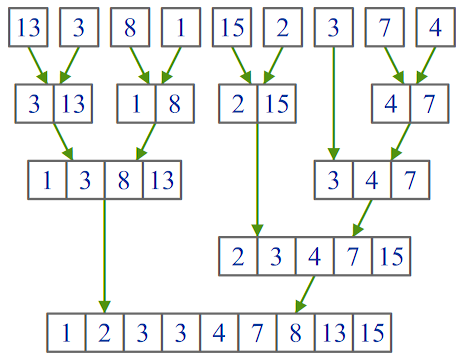

[Источник изображения](https://neerc.ifmo.ru/wiki/index.php?title=Файл:Merge_sort1.png)

In [19]:
def merge(left, right):
    lf = 0
    rg = 0
    res = []
    while lf < len(left) and rg < len(right):
        if left[lf] < right[rg]:
            res.append(left[lf])
            lf += 1
        else:
            res.append(right[rg])
            rg += 1
    while lf < len(left):
        res.append(left[lf])
        lf += 1
    while rg < len(right):
        res.append(right[rg])
        rg += 1
    return res

def merge_sort(arr):
    if len(arr) <= 1:
        return arr

    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])
    return merge(left, right)

In [23]:
merge_sort([9, 8, 7, 6, 5, 4, 3])
sort(...)

[3, 4, 5, 6, 7, 8, 9]

## Как оценивать сложность рекурсивных программ

Мастер-теорема:
$T(n)$ -- время работы программы для входа размера $n$

$$
T(n) = a T(n/b) + O(n^c), \ n > 1
$$

$$
T(n) = O(1), \ n = 1
$$

где $a \in \mathbb{N}$, $b \in \mathbb{R}$, $b>1$, $c \in \mathbb{R}+$

Тогда $T(n)$ имеет вид:

Если $c > \log_b(a)$, то $T(n)=O(n^c)$

Если $c=\log_b(a)$, то $T(n)=O(n^c\log n)$

Если $c < \log_b(a)$, то $T(n)=O(n^{\log_b(a)})$

Применим теорему для сортировки слиянием:

$a = 2, b = 2, c = 1$

$log_b(a) = log_2(2) = 1$

$c = 1 = log_b(a) ⇒ T(n) = O(n^1 \log n) = O(n \log n)$

Больше о мастер-теореме можно прочитать [тут](https://neerc.ifmo.ru/wiki/index.php?title=Мастер-теорема)

## Хвостовая рекурсия

Хвостовая рекурсия -- рекурсивный вызов производится последним действием рекурсивной функции

Некоторые языки умеют автоматически превращать такую рекурсию в обычный цикл

Попробуем сделать это руками

In [24]:
def factorial(n):
    if n == 1:
        return 1
    return n * factorial(n - 1)


def linear_factorial(n):
    current_factorial = 1
    for i in range(2, n + 1):
        current_factorial *= i
    return current_factorial

In [26]:
%timeit factorial(30)

2.54 µs ± 61.5 ns per loop (mean ± std. dev. of 7 runs, 100000 loops each)


In [27]:
%timeit linear_factorial(30)

1.72 µs ± 340 ns per loop (mean ± std. dev. of 7 runs, 1000000 loops each)


In [28]:
def factorial_tail(a, b=1):
    if a == 1:
        return b
    do_sth...
    return factorial_tail(a - 1, a * b)

In [29]:
factorial_tail(5)

120

In [53]:
def factorial_tail_linear(a, b=1):
    while a != 1:
        do_sth...
        b = a * b
        a = a - 1
    return b

In [54]:
factorial_tail_linear(5)

120

Глубокая рекурсия приводит к разрастанию стека

https://docs.python.org/3/library/sys.html#sys.setrecursionlimit